In [ ]:
# Mini-projet : prédiction du taux de criminalité violente (Communities and Crime)

**Module :** Technologies IA, ENSA Fès, ILIA2
**Réalisé par :** [Nom 1] et [Nom 2]

## Introduction

La criminalité violente varie fortement d'une communauté à l'autre, et comprendre
les facteurs socio-économiques qui lui sont associés est un enjeu important pour
les politiques publiques. Dans ce mini-projet, nous cherchons à **prédire le taux
de crimes violents par habitant** d'une communauté à partir de ses
caractéristiques démographiques et socio-économiques. Il s'agit d'un problème de
**régression supervisée** : la variable cible est numérique et continue.

**Données.** Nous utilisons le jeu de données *Communities and Crime* du dépôt UCI
Machine Learning Repository. Il rassemble 1994 communautés américaines décrites
par 128 attributs : données du recensement (revenus, pauvreté, structure
familiale, logement, éducation, composition de la population), informations issues
d'une enquête sur les forces de police, et taux de criminalité. La variable à
prédire est `ViolentCrimesPerPop`, normalisée entre 0 et 1.

**Démarche.** Nous appliquons le workflow complet d'un apprentissage supervisé :
1. chargement des données et exploration (valeurs manquantes, distribution de la
   cible) ;
2. nettoyage : suppression des variables d'identification et des variables trop
   incomplètes ;
3. séparation en un jeu d'entraînement (80 %) et un jeu de test (20 %) ;
4. définition d'un modèle de référence (baseline) ;
5. comparaison de plusieurs modèles (régression linéaire, Ridge, Lasso, Random
   Forest, Gradient Boosting) par validation croisée ;
6. évaluation finale du modèle retenu sur le jeu de test, avec les métriques
   MAE, RMSE et R², puis interprétation et conclusion critique.

**Objectif.** Déterminer quel modèle retenir, et pourquoi, en comparant ses
performances à celles d'une baseline et en discutant les limites des données et
des résultats.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
data = pd.read_csv('communities.data', header=None, na_values='?')
print(data.shape)
data.head()

(1994, 128)


,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [5]:
# header=None : le fichier n'a pas de ligne de noms de colonnes
# na_values='?' : les valeurs manquantes sont écrites avec un point d'interrogation
#pour un tout premier regard il faut identifier les types et combien de valeur manquante
print(data.dtypes.value_counts())
print("Total de valeurs manquantes :", data.isnull().sum().sum())

float64    125
int64        2
str          1
Name: count, dtype: int64
Total de valeurs manquantes : 39202


In [6]:
#puisque le fichier communities.names contient les entêtes on va l'utiliser 
with open('communities.names', encoding='utf-8', errors='ignore') as f:
    noms = [ligne.split()[1] for ligne in f if ligne.startswith('@attribute')]

print(len(noms))      
data.columns = noms
data.head()

128


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [7]:
manquantes = data.isnull().sum()
pct = (manquantes / len(data) * 100).round(1)
resume = pd.DataFrame({'manquantes': manquantes, '%': pct})
resume = resume[resume['manquantes'] > 0].sort_values('%', ascending=False)

print(len(resume), "colonnes avec des valeurs manquantes")
resume

25 colonnes avec des valeurs manquantes


,manquantes,%
LemasSwFTPerPop,1675,84.0
LemasTotalReq,1675,84.0
LemasSwornFT,1675,84.0
LemasSwFTFieldPerPop,1675,84.0
LemasSwFTFieldOps,1675,84.0
LemasTotReqPerPop,1675,84.0
RacialMatchCommPol,1675,84.0
PolicPerPop,1675,84.0
PolicReqPerOffic,1675,84.0
OfficAssgnDrugUnits,1675,84.0


count    1994.000000
mean        0.237979
std         0.232985
min         0.000000
25%         0.070000
50%         0.150000
75%         0.330000
max         1.000000
Name: ViolentCrimesPerPop, dtype: float64


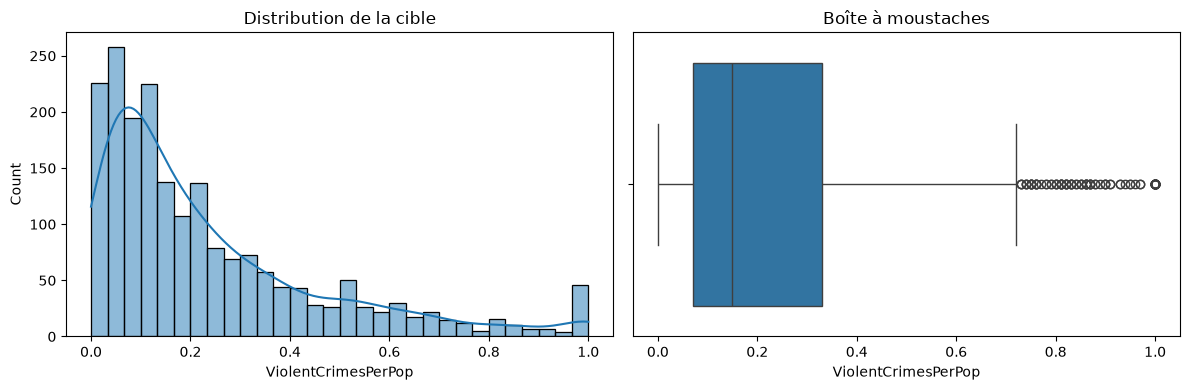

In [8]:
y = data['ViolentCrimesPerPop']
print(y.describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y, bins=30, kde=True, ax=axes[0])
axes[0].set_title('Distribution de la cible')
sns.boxplot(x=y, ax=axes[1])
axes[1].set_title('Boîte à moustaches')
plt.tight_layout()
plt.show()

In [ ]:
La cible est asymétrique (médiane 0,15, quartile supérieur 0,33) avec un plafonnement à 1,0 dû à la normalisation. Les valeurs élevées sont conservées car ce sont des communautés réelles.

In [9]:
colonnes_non_predictives = ['state', 'county', 'community', 'communityname', 'fold']

X = data.drop(columns=colonnes_non_predictives + ['ViolentCrimesPerPop'])
y = data['ViolentCrimesPerPop']

print(X.shape)  

(1994, 122)


In [10]:
colonnes_non_predictives = ['state', 'county', 'community', 'communityname', 'fold']

X = data.drop(columns=colonnes_non_predictives + ['ViolentCrimesPerPop'])
y = data['ViolentCrimesPerPop']
print("Après retrait des colonnes non prédictives :", X.shape)   # attendu (1994, 122)

# colonnes avec plus de 80 % de valeurs manquantes
cols_police = [c for c in resume.index[resume['%'] > 80] if c in X.columns]
print(len(cols_police), "colonnes supprimées")                   # attendu 22

X = X.drop(columns=cols_police)
print("Après suppression des colonnes manquantes :", X.shape)    # attendu (1994, 100)

# ce qui reste comme valeurs manquantes
restantes = X.isnull().sum()
restantes[restantes > 0]  

Après retrait des colonnes non prédictives : (1994, 122)
22 colonnes supprimées
Après suppression des colonnes manquantes : (1994, 100)


OtherPerCap    1
dtype: int64

In [ ]:
22 variables issues de l’enquête policière (LEMAS) ont 84 % de valeurs manquantes,
et ce manque n’est pas aléatoire (l’enquête couvre surtout les grands services). 
Elles sont supprimées plutôt qu’imputées. Conséquence : le modèle ne peut pas évaluer l’effet des moyens de police.
Il reste 100 variables explicatives, et OtherPerCap (1 valeur manquante) sera imputée par la médiane du jeu d’entraînement dans un pipeline.

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train :", X_train.shape, y_train.shape)
print("Test  :", X_test.shape, y_test.shape)

Train : (1595, 100) (1595,)
Test  : (399, 100) (399,)


In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

print("MAE  =", round(mean_absolute_error(y_test, y_pred_dummy), 4))
print("RMSE =", round(np.sqrt(mean_squared_error(y_test, y_pred_dummy)), 4))
print("R²   =", round(r2_score(y_test, y_pred_dummy), 4))

In [ ]:
Séparation 80 % / 20 % avec random_state=42. Le modèle de référence prédit la moyenne du train : c’est le niveau minimal à dépasser.

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2',
}

def make_pipe(model):
    return Pipeline([
        ('imp', SimpleImputer(strategy='median')),   # impute OtherPerCap, appris sur le train du pli
        ('sc', StandardScaler()),                    # mise à l'échelle
        ('model', model),
    ])

modeles = {
    'Baseline (moyenne)': DummyRegressor(strategy='mean'),
    'Régression linéaire': LinearRegression(),
    'Ridge (alpha=10)': Ridge(alpha=10),
    'Lasso (alpha=0.001)': Lasso(alpha=0.001, max_iter=10000),
}

lignes = []
for nom, m in modeles.items():
    res = cross_validate(make_pipe(m), X_train, y_train, cv=cv, scoring=scoring)
    lignes.append({
        'Modèle': nom,
        'MAE': -res['test_MAE'].mean(),
        'MAE std': res['test_MAE'].std(),
        'RMSE': -res['test_RMSE'].mean(),
        'R²': res['test_R2'].mean(),
        'R² std': res['test_R2'].std(),
    })

comparaison = pd.DataFrame(lignes).round(4)
comparaison

,Modèle,MAE,MAE std,RMSE,R²,R² std
0,Baseline (moyenne),0.1808,0.0075,0.2358,-0.0023,0.0019
1,Régression linéaire,0.0993,0.0034,0.1395,0.6483,0.0318
2,Ridge (alpha=10),0.0972,0.0034,0.1378,0.6567,0.0299
3,Lasso (alpha=0.001),0.0964,0.0035,0.1382,0.6546,0.0301


In [ ]:
Les trois modèles linéaires réduisent l’erreur de moitié par rapport à la baseline (MAE ≈ 0,097 contre 0,181, R² ≈ 0,65).
Ridge et Lasso sont légèrement meilleurs que la régression simple,mais l’écart est inférieur à la variabilité entre plis : on ne peut pas les départager à ce stade.

In [17]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

modeles = {
    'Baseline (moyenne)': DummyRegressor(strategy='mean'),
    'Régression linéaire': LinearRegression(),
    'Ridge (alpha=10)': Ridge(alpha=10),
    'Lasso (alpha=0.001)': Lasso(alpha=0.001, max_iter=10000),
    'Random Forest': RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
}

lignes = []
mae_plis = {}     # MAE de chaque pli, par modèle
for nom, m in modeles.items():
    res = cross_validate(make_pipe(m), X_train, y_train, cv=cv, scoring=scoring)
    mae_plis[nom] = -res['test_MAE']
    lignes.append({
        'Modèle': nom,
        'MAE': -res['test_MAE'].mean(),
        'MAE std': res['test_MAE'].std(),
        'RMSE': -res['test_RMSE'].mean(),
        'R²': res['test_R2'].mean(),
        'R² std': res['test_R2'].std(),
    })

comparaison = pd.DataFrame(lignes).round(4)
comparaison

,Modèle,MAE,MAE std,RMSE,R²,R² std
0,Baseline (moyenne),0.1808,0.0075,0.2358,-0.0023,0.0019
1,Régression linéaire,0.0993,0.0034,0.1395,0.6483,0.0318
2,Ridge (alpha=10),0.0972,0.0034,0.1378,0.6567,0.0299
3,Lasso (alpha=0.001),0.0964,0.0035,0.1382,0.6546,0.0301
4,Random Forest,0.0955,0.0046,0.1375,0.6571,0.0392
5,Gradient Boosting,0.0946,0.0056,0.1376,0.6569,0.0428


In [ ]:
### Choix du modèle : Ridge

Nous retenons la régression Ridge. Les modèles ont été comparés par validation
croisée à 5 plis sur le jeu d'entraînement : chaque modèle a été entraîné et
évalué 5 fois, et le tableau donne la moyenne des erreurs et leur écart-type.
Tous les modèles réduisent l'erreur de moitié par rapport à la baseline
(MAE de 0,181), mais ils se ressemblent beaucoup entre eux. Ridge obtient une MAE
de 0,0972, une RMSE de 0,1378 et un R² de 0,657, contre 0,0946, 0,1376 et 0,657
pour le Gradient Boosting, et 0,0955, 0,1375 et 0,657 pour le Random Forest.
Le Gradient Boosting a bien la MAE la plus basse, mais l'écart avec Ridge (environ
0,003 sur une échelle de 0 à 1) est plus petit que l'écart-type de la MAE d'un
découpage à l'autre (0,003 à 0,006), et la RMSE et le R² sont pratiquement
identiques pour les trois modèles. Les modèles à arbres n'apportent donc pas de
gain net. Dans ces conditions, nous préférons Ridge : il est plus simple, plus
rapide à entraîner, plus stable d'un découpage à l'autre (écart-type du R² de
0,030 contre 0,039 et 0,043 pour les modèles à arbres), et ses coefficients
permettent d'interpréter l'influence de chaque variable. Nous reconnaissons que
si la précision de la prédiction était la seule priorité, le Gradient Boosting
serait un choix défendable.

In [29]:
modele_final = make_pipe(Ridge(alpha=10))
modele_final.fit(X_train, y_train)
y_pred = modele_final.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f"Ridge sur le test : MAE = {mae:.4f} | RMSE = {rmse:.4f} | R² = {r2:.4f}")
print("Baseline sur le test : MAE = 0.1788 | RMSE = 0.2212 | R² = -0.0217")

Ridge sur le test : MAE = 0.0935 | RMSE = 0.1314 | R² = 0.6393
Baseline sur le test : MAE = 0.1788 | RMSE = 0.2212 | R² = -0.0217


Ridge sur le test : MAE = 0.0935 | RMSE = 0.1314 | R² = 0.6393


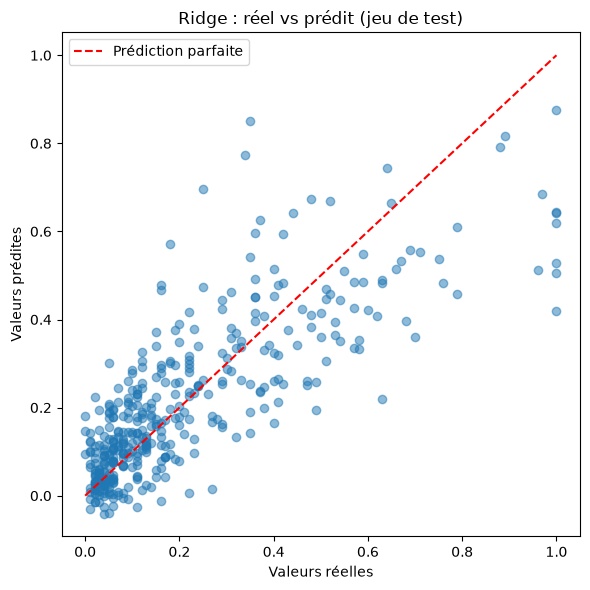

In [30]:
# Modèle retenu : Ridge (alpha=10), entraîné sur le train uniquement
modele_final = make_pipe(Ridge(alpha=10))
modele_final.fit(X_train, y_train)
y_pred = modele_final.predict(X_test)

# Métriques sur le jeu de test (évaluation finale)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print(f"Ridge sur le test : MAE = {mae:.4f} | RMSE = {rmse:.4f} | R² = {r2:.4f}")

# Graphique réel vs prédit
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([0, 1], [0, 1], 'r--', label='Prédiction parfaite')
plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Ridge : réel vs prédit (jeu de test)')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
Les prédictions suivent globalement la diagonale (R² ≈ 0.6393), mais le modèle sous-estime les communautés à très forte criminalité et l’erreur augmente avec la valeur réelle.

In [ ]:
## Conclusion générale

Ce projet visait à prédire le taux de crimes violents des communautés américaines
à partir de 100 variables socio-économiques et démographiques. Après nettoyage
(suppression des 22 variables issues de l'enquête policière, manquantes à 84 %, et
des colonnes identification) et séparation en jeux d'entraînement et de test,
les modèles ont été comparés à une baseline par validation croisée. Le modèle
retenu, Ridge, obtient sur le jeu de test une MAE de 0.0935, une RMSE de 0.1314 et un
R² de 0.6393, contre 0,179, 0,221 et -0,02 pour la baseline : il explique environ
les deux tiers de la variation du taux de criminalité. Ce résultat doit toutefois
être nuancé. Les modèles plafonnent tous autour du même score, ce qui suggère que
la limite vient des variables disponibles plus que du choix du modèle. Les
données datent de 1990-1995 et sont agrégées par communauté, donc aucune
conclusion ne s'applique à des individus. La cible est plafonnée à 1,0 par la
normalisation, et le modèle sous-estime les communautés à très forte
criminalité. Enfin, les variables étant très corrélées, les coefficients ne
traduisent pas des relations causales, et l'utilisation de variables liées à la
composition ethnique pose un problème d'équité. Parmi les pistes
d'amélioration figurent un réglage plus fin des hyperparamètres, l'ajout de la
variable `state` et l'analyse des erreurs par groupe de communautés.